#Q1

Obtain the daily closing prices of Brent Crude Oil for the period 1 January 2024 to 31 December 2024 Perform the following tasks:

In [ ]:
pip install yfinance

In [ ]:
import yfinance as yf
import pandas as pd

ticker = "BZ=F"
start_date = "2024-01-01"
end_date = "2025-01-01"

brent_data = yf.download(ticker, start=start_date, end=end_date)

# Flatten multi-level column index if it exists
if isinstance(brent_data.columns, pd.MultiIndex):
    brent_data.columns = brent_data.columns.get_level_values(0)

# Reset index to make 'Date' a column
brent_data.reset_index(inplace=True)

/tmp/ipykernel_898/566943717.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  brent_data = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


In [ ]:
missing_count = brent_data.isnull().sum().sum()
print(f"Missing values found: {missing_count}")

# Remove missing values (if any)
brent_data.dropna(inplace=True)

# Preprocess: Arrange in chronological order
brent_data.sort_values(by='Date', ascending=True, inplace=True)

print("\nDataset Info:")
print(brent_data.info())

print("\nFirst 5 rows of preprocessed data:")
brent_data.head()

Missing values found: 0

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 252 entries, 0 to 251
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    252 non-null    datetime64[ns]
 1   Close   252 non-null    float64       
 2   High    252 non-null    float64       
 3   Low     252 non-null    float64       
 4   Open    252 non-null    float64       
 5   Volume  252 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 11.9 KB
None

First 5 rows of preprocessed data:


Price,Date,Close,High,Low,Open,Volume
0,2024-01-02,75.889999,79.040001,75.599998,77.209999,28591
1,2024-01-03,78.250000,78.669998,74.790001,75.989998,32172
2,2024-01-04,77.589996,79.400002,76.500000,78.500000,33154
3,2024-01-05,78.760002,79.250000,77.500000,77.599998,30994
4,2024-01-08,76.120003,78.949997,75.260002,78.599998,32539


(i) Compute the following Simple Moving Averages (SMA): 5-day SMA, 10-day SMA, 20-day SMA, 50-day SMA

In [ ]:
import pandas as pd

# Compute the Simple Moving Averages
brent_data['SMA_5'] = brent_data['Close'].rolling(window=5).mean()
brent_data['SMA_10'] = brent_data['Close'].rolling(window=10).mean()
brent_data['SMA_20'] = brent_data['Close'].rolling(window=20).mean()
brent_data['SMA_50'] = brent_data['Close'].rolling(window=50).mean()

brent_data

Price,Date,Close,High,Low,Open,Volume,SMA_5,SMA_10,SMA_20,SMA_50
0,2024-01-02,75.889999,79.040001,75.599998,77.209999,28591,NaN,NaN,NaN,NaN
1,2024-01-03,78.250000,78.669998,74.790001,75.989998,32172,NaN,NaN,NaN,NaN
2,2024-01-04,77.589996,79.400002,76.500000,78.500000,33154,NaN,NaN,NaN,NaN
3,2024-01-05,78.760002,79.250000,77.500000,77.599998,30994,NaN,NaN,NaN,NaN
4,2024-01-08,76.120003,78.949997,75.260002,78.599998,32539,77.322,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
247,2024-12-24,73.580002,73.809998,72.779999,72.839996,8922,73.084,73.394000,72.891000,73.3466
248,2024-12-26,73.260002,74.180000,72.980003,73.779999,5773,73.058,73.368001,72.913501,73.3268
249,2024-12-27,74.169998,74.339996,73.070000,73.139999,5515,73.316,73.444000,72.980500,73.3258
250,2024-12-30,74.389999,75.040001,73.760002,74.230003,30436,73.606,73.434000,73.053000,73.3246


(ii) Plot the original closing price together with all the moving average curves on the same graph. Compare the smoothing effect of each moving average and identify the periods during which the closing price remained above and below the 20-day moving average.

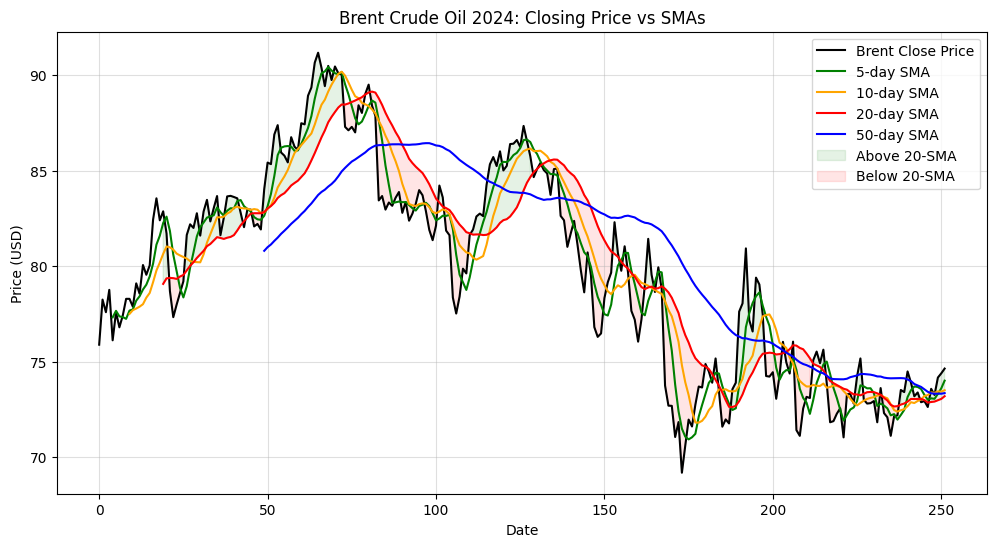

In [ ]:
import matplotlib.pyplot as plt

# Plotting
plt.figure(figsize=(12, 6))

plt.plot(brent_data.index, brent_data['Close'], label='Brent Close Price', color='black')
plt.plot(brent_data.index, brent_data['SMA_5'], label='5-day SMA', color='green')
plt.plot(brent_data.index, brent_data['SMA_10'], label='10-day SMA', color='orange')
plt.plot(brent_data.index, brent_data['SMA_20'], label='20-day SMA', color='red')
plt.plot(brent_data.index, brent_data['SMA_50'], label='50-day SMA', color='blue')

# Highlight periods where Price is above/below SMA_20
plt.fill_between(brent_data.index, brent_data['Close'], brent_data['SMA_20'],
                 where=(brent_data['Close'] > brent_data['SMA_20']), color='green', alpha=0.1, label='Above 20-SMA')
plt.fill_between(brent_data.index, brent_data['Close'], brent_data['SMA_20'],
                 where=(brent_data['Close'] < brent_data['SMA_20']), color='red', alpha=0.1, label='Below 20-SMA')

plt.title('Brent Crude Oil 2024: Closing Price vs SMAs')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

(iii) Treat the opening price as the independent variable and the daily closing price as the dependent variable. Develop the linear regression model.

In [ ]:
from sklearn.linear_model import LinearRegression

close = brent_data['Close'].values
open = brent_data['Open'].values

linear_regression_model = LinearRegression().fit(open.reshape(-1, 1), close)
intercept = linear_regression_model.intercept_
coeff = linear_regression_model.coef_

print(f"Linear Regression Model: Close = {intercept:.4f} + {coeff[0]:.4f}*Open")

Linear Regression Model: Close = 1.5563 + 0.9803*Open


(iv) Evaluate regression model using:
* Coefficient of Determination (R2)
* Root Mean Square Error (RMSE)
* Mean Absolute Error (MAE)

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

y_true = close
y_pred = linear_regression_model.predict(open.reshape(-1, 1))

r2 = r2_score(y_true, y_pred)
rmse = mean_squared_error(y_true, y_pred)
mae = mean_absolute_error(y_true, y_pred)

print(f"Coefficient of Determination (R2): {r2:.4f}")
print(f"Root Mean Square Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

Coefficient of Determination (R2): 0.9512
Root Mean Square Error (RMSE): 1.4119
Mean Absolute Error (MAE): 0.9419


(v) Superimpose the 20-day Simple Moving Average and the regression curve on the same graph. Compare the smoothing and trend-identification capabilities of the moving average and regression approaches.

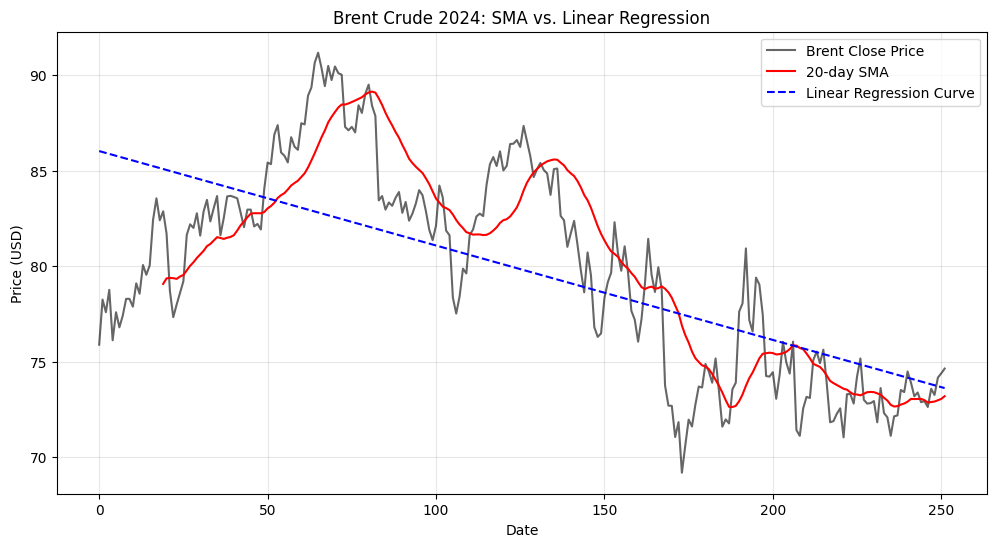


Regression Slope (Open vs Close): 0.9803
A slope near 1.0 indicates a strong 1-to-1 relationship between the Open and Close price.


In [ ]:
import numpy as np

time_data = np.arange(len(brent_data.index)).reshape(-1,1)
linear_reg = LinearRegression().fit(time_data, brent_data['Close'])
y_pred_1 = linear_reg.predict(time_data)

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(brent_data.index, brent_data['Close'], label='Brent Close Price', color='black', alpha=0.6)
plt.plot(brent_data.index, brent_data['SMA_20'], label='20-day SMA', color='red', linewidth=1.5)
plt.plot(brent_data.index, y_pred_1, label='Linear Regression Curve', color='blue', linestyle='--', linewidth=1.5)

plt.title('Brent Crude 2024: SMA vs. Linear Regression')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nRegression Slope (Open vs Close): {linear_regression_model.coef_[0]:.4f}")
print("A slope near 1.0 indicates a strong 1-to-1 relationship between the Open and Close price.")

#Q2

Obtain the daily USD/INR exchange rate for the period 1 January 2024 to 31 December 2024. Perform the following tasks:

In [17]:
import yfinance as yf
import pandas as pd

# 1. Define the ticker for USD/INR
ticker = "USDINR=X"

# 2. Download the data for 2024
usd_inr_data = yf.download(ticker, start="2024-01-01", end="2025-01-01")

# 3. Flatten the multi-level column index
if isinstance(usd_inr_data.columns, pd.MultiIndex):
    usd_inr_data.columns = usd_inr_data.columns.get_level_values(0)

usd_inr_data.reset_index(inplace=True)

# 4. Preprocess: Arrange in chronological order
usd_inr_data.sort_values(by='Date', ascending=True, inplace=True)

print("\nDataset Info:")
print(usd_inr_data.info())

print("\nFirst 5 rows of preprocessed data:")
usd_inr_data.head()

/tmp/ipykernel_898/2481837912.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  usd_inr_data = yf.download(ticker, start="2024-01-01", end="2025-01-01")
[*********************100%***********************]  1 of 1 completed


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    262 non-null    datetime64[ns]
 1   Close   262 non-null    float64       
 2   High    262 non-null    float64       
 3   Low     262 non-null    float64       
 4   Open    262 non-null    float64       
 5   Volume  262 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 12.4 KB
None

First 5 rows of preprocessed data:


Price,Date,Close,High,Low,Open,Volume
0,2024-01-01,83.248596,83.237999,83.150002,83.248596,0
1,2024-01-02,83.202599,83.343002,83.169800,83.202599,0
2,2024-01-03,83.257004,83.333702,83.246201,83.257004,0
3,2024-01-04,83.318100,83.360298,83.202103,83.318100,0
4,2024-01-05,83.240601,83.271599,83.035004,83.240601,0


(i) Compute the following Simple Moving Averages (SMA):
* 7-day SMA
* 14-day SMA
* 30-day SMA

In [18]:
import pandas as pd

# Compute the Simple Moving Averages
usd_inr_data['SMA_7'] = usd_inr_data['Close'].rolling(window=7).mean()
usd_inr_data['SMA_14'] = usd_inr_data['Close'].rolling(window=14).mean()
usd_inr_data['SMA_30'] = usd_inr_data['Close'].rolling(window=30).mean()

usd_inr_data

Price,Date,Close,High,Low,Open,Volume,SMA_7,SMA_14,SMA_30
0,2024-01-01,83.248596,83.237999,83.150002,83.248596,0,NaN,NaN,NaN
1,2024-01-02,83.202599,83.343002,83.169800,83.202599,0,NaN,NaN,NaN
2,2024-01-03,83.257004,83.333702,83.246201,83.257004,0,NaN,NaN,NaN
3,2024-01-04,83.318100,83.360298,83.202103,83.318100,0,NaN,NaN,NaN
4,2024-01-05,83.240601,83.271599,83.035004,83.240601,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
257,2024-12-25,85.181503,85.547203,82.745003,85.181503,0,85.071857,84.933743,84.694763
258,2024-12-26,85.413399,85.420303,85.010002,85.413399,0,85.142729,84.985857,84.727777
259,2024-12-27,85.260902,85.817802,81.507401,85.260902,0,85.192086,85.028350,84.754014
260,2024-12-30,85.386002,85.584999,85.263901,85.386002,0,85.223587,85.066829,84.784297


(ii) Plot the original exchange rate together with the 7-day, 14-day and 30-day moving average curves on the same graph. Identify the periods of appreciation and depreciation of the Indian Rupee and compare the effect of different moving average windows in smoothing short-term fluctuations.

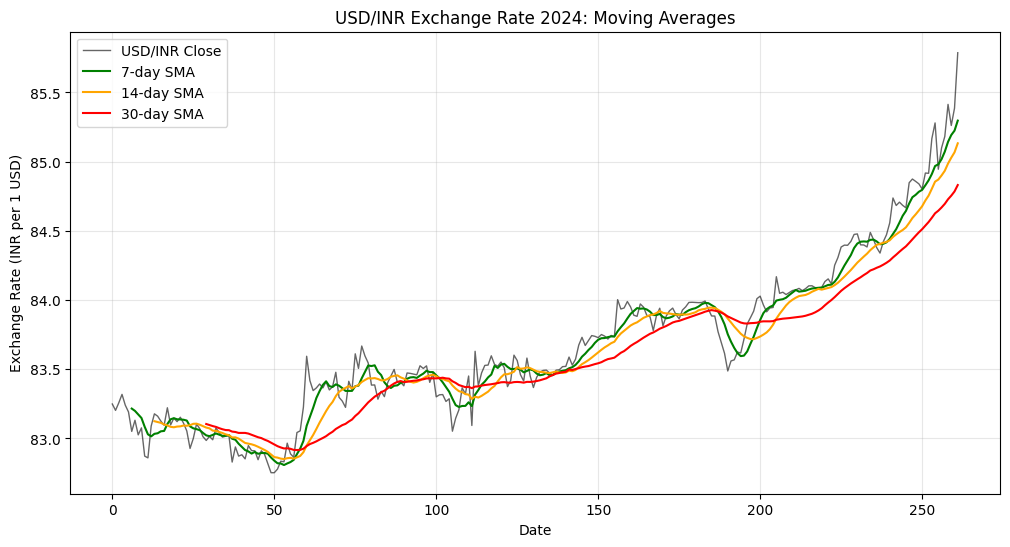

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Plot Original Closing Price
plt.plot(usd_inr_data.index, usd_inr_data['Close'], label='USD/INR Close', color='black', alpha=0.6, linewidth=1)

# Plot SMAs
plt.plot(usd_inr_data.index, usd_inr_data['SMA_7'], label='7-day SMA', color='green', linewidth=1.5)
plt.plot(usd_inr_data.index, usd_inr_data['SMA_14'], label='14-day SMA', color='orange', linewidth=1.5)
plt.plot(usd_inr_data.index, usd_inr_data['SMA_30'], label='30-day SMA', color='red', linewidth=1.5)

plt.title('USD/INR Exchange Rate 2024: Moving Averages')
plt.xlabel('Date')
plt.ylabel('Exchange Rate (INR per 1 USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# 1. Rupee Movement Interpretation
#   Key Rule: In USD/INR, an Upward move = Rupee Depreciation (weakening). A Downward move = Rupee Appreciation (strengthening).
#   Appreciation Period: Day 0 to ~55 (Price drops from 83.3 to 82.8).
#   Depreciation Period: Day 210 to End (Price spikes sharply from 84.0 toward 85.8).

# 2. Smoothing Effect Comparison
#   7-Day SMA (Green): High sensitivity, low smoothing. It follows the daily "noise" and zig-zags closely with the price.
#   14-Day SMA (Orange): Moderate smoothing. It filters out one-day spikes but still reacts to two-week trends.
#   30-Day SMA (Red): Maximum smoothing. It produces the flattest curve and ignores all short-term volatility.

# Conclusion:
# As the SMA window increases, the smoothing improves (less noise), but the responsiveness decreases (more lag).
# The 30-day SMA is best for identifying the "big picture" trend, while the 7-day is better for seeing immediate price shifts.

(iii) Treat the opening exchange rate as the independent variable and the closing exchange rate as the
dependent variable. Develop the following regression models:
* (a) Linear Regression
* (b) Quadratic Regression
* (c) Cubic Regression

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

open = usd_inr_data['Open'].values
close = usd_inr_data['Close'].values

# Linear regression
linear_reg = LinearRegression().fit(open.reshape(-1, 1), close)
intercept = linear_reg.intercept_
coeff = linear_reg.coef_
print(f"Linear Regression Model: Close = {intercept:.4f} + {coeff[0]:.4f}*Open")

# Quadratic regression
poly2 = PolynomialFeatures(degree=2, include_bias=False)
open_quadratic = poly2.fit_transform(open.reshape(-1, 1))
quadratic_reg = LinearRegression().fit(open_quadratic, close)
intercept = quadratic_reg.intercept_
coeff = quadratic_reg.coef_
print(f"Quadratic Regression Model: Close = {intercept:.4f} + {coeff[0]:.4f}*Open + {coeff[1]:.4f}*Open^2")

# Cubic regression
poly3 = PolynomialFeatures(degree=3, include_bias=False)
open_cubic = poly3.fit_transform(open.reshape(-1, 1))
cubic_reg = LinearRegression().fit(open_cubic, close)
intercept = cubic_reg.intercept_
coeff = cubic_reg.coef_
print(f"Cubic Regression Model: Close = {intercept:.4f} + {coeff[0]:.4f}*Open + {coeff[1]:.4f}*Open^2 + {coeff[2]:.4f}*Open^3")

Linear Regression Model: Close = 0.0000 + 1.0000*Open
Quadratic Regression Model: Close = 0.0000 + 1.0000*Open + 0.0000*Open^2
Cubic Regression Model: Close = -0.0000 + 1.0000*Open + -0.0000*Open^2 + 0.0000*Open^3


(iv) Plot the fitted regression curves together with the original exchange rate data on the same graph.

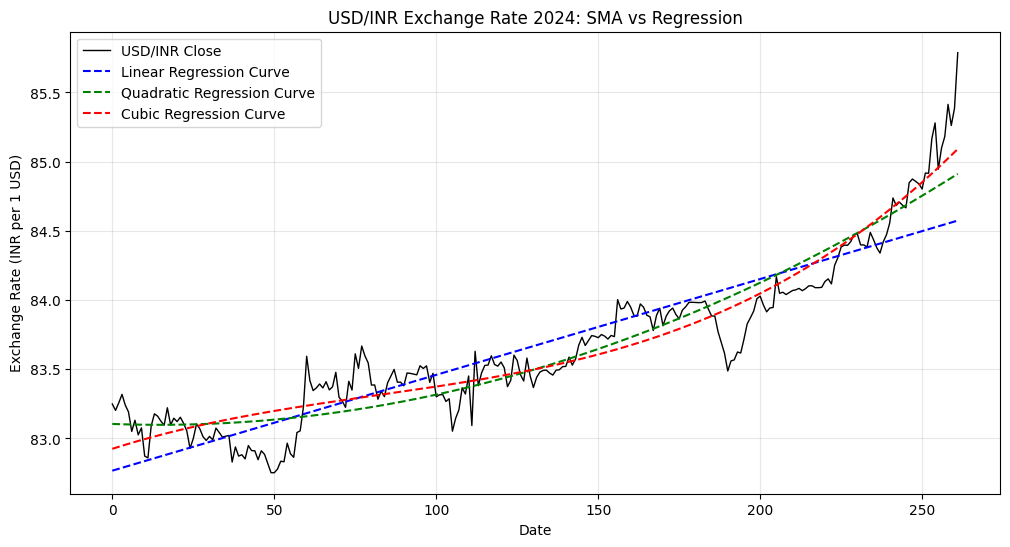

In [21]:
import numpy as np

time_data = np.arange(len(usd_inr_data.index)).reshape(-1,1)
linear_reg_model = LinearRegression().fit(time_data, usd_inr_data['Close'])
y_pred_1 = linear_reg_model.predict(time_data)

quadratic_reg_model = LinearRegression().fit(poly2.fit_transform(time_data), usd_inr_data['Close'])
y_pred_2 = quadratic_reg_model.predict(poly2.fit_transform(time_data))

cubic_reg_model = LinearRegression().fit(poly3.fit_transform(time_data), usd_inr_data['Close'])
y_pred_3 = cubic_reg_model.predict(poly3.fit_transform(time_data))

plt.figure(figsize=(12, 6))

# Plot Original Closing Price
plt.plot(usd_inr_data.index, usd_inr_data['Close'], label='USD/INR Close', color='black', linewidth=1)

# Plot fitted regression
plt.plot(usd_inr_data.index, y_pred_1, label='Linear Regression Curve', color='blue', linestyle='--', linewidth=1.5)
plt.plot(usd_inr_data.index, y_pred_2, label='Quadratic Regression Curve', color='green', linestyle='--', linewidth=1.5)
plt.plot(usd_inr_data.index, y_pred_3, label='Cubic Regression Curve', color='red', linestyle='--', linewidth=1.5)

plt.title('USD/INR Exchange Rate 2024: SMA vs Regression')
plt.xlabel('Date')
plt.ylabel('Exchange Rate (INR per 1 USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

(v) Superimpose the 30-day Simple Moving Average and the three regression curves on a single graph. Compare how the moving average and each regression model represent the overall trend of the USD/INR exchange rate.

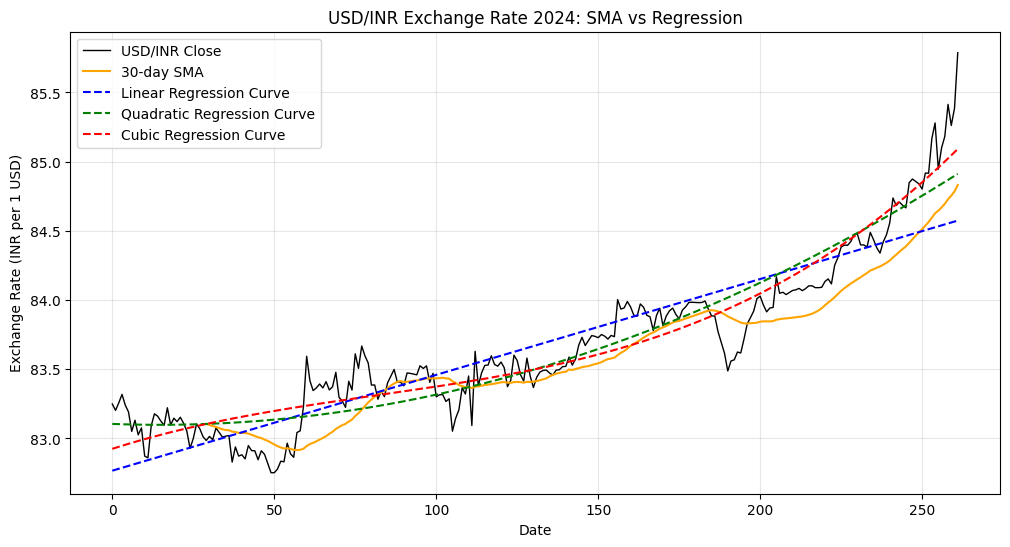

In [22]:
plt.figure(figsize=(12, 6))

plt.plot(usd_inr_data.index, usd_inr_data['Close'], label='USD/INR Close', color='black', linewidth=1)
plt.plot(usd_inr_data.index, usd_inr_data['SMA_30'], label='30-day SMA', color='orange', linewidth=1.5)

plt.plot(usd_inr_data.index, y_pred_1, label='Linear Regression Curve', color='blue', linestyle='--', linewidth=1.5)
plt.plot(usd_inr_data.index, y_pred_2, label='Quadratic Regression Curve', color='green', linestyle='--', linewidth=1.5)
plt.plot(usd_inr_data.index, y_pred_3, label='Cubic Regression Curve', color='red', linestyle='--', linewidth=1.5)

plt.title('USD/INR Exchange Rate 2024: SMA vs Regression')
plt.xlabel('Date')
plt.ylabel('Exchange Rate (INR per 1 USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

(vi) Evaluate the regression models using:
* Coefficient of Determination (R2)
* Root Mean Square Error (RMSE)
* Mean Absolute Error (MAE)

In [23]:
# Evaluating the open-vs-close regression models

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

y_true = usd_inr_data['Close'].values
y_pred_linear = linear_reg.predict(open.reshape(-1, 1))
y_pred_quadratic = quadratic_reg.predict(poly2.fit_transform(open.reshape(-1, 1)))
y_pred_cubic = cubic_reg.predict(poly3.fit_transform(open.reshape(-1, 1)))

# Linear
linear_r2 = r2_score(y_true, y_pred_linear)
linear_rmse = mean_squared_error(y_true, y_pred_linear)
linear_mae = mean_absolute_error(y_true, y_pred_linear)
print(f"----- Linear regression -----")
print(f"Coefficient of Determination (R2): {linear_r2:.4f}")
print(f"Root Mean Square Error (RMSE): {linear_rmse:.4f}")
print(f"Mean Absolute Error (MAE): {linear_mae:.4f}")

# Quadratic
quadratic_r2 = r2_score(y_true, y_pred_quadratic)
quadratic_rmse = mean_squared_error(y_true, y_pred_quadratic)
quadratic_mae = mean_absolute_error(y_true, y_pred_quadratic)
print(f"\n----- Quadratic regression -----")
print(f"Coefficient of Determination (R2): {quadratic_r2:.4f}")
print(f"Root Mean Square Error (RMSE): {quadratic_rmse:.4f}")
print(f"Mean Absolute Error (MAE): {quadratic_mae:.4f}")

# Cubic
cubic_r2 = r2_score(y_true, y_pred_cubic)
cubic_rmse = mean_squared_error(y_true, y_pred_cubic)
cubic_mae = mean_absolute_error(y_true, y_pred_cubic)
print(f"\n----- Cubic regression -----")
print(f"Coefficient of Determination (R2): {cubic_r2:.4f}")
print(f"Root Mean Square Error (RMSE): {cubic_rmse:.4f}")
print(f"Mean Absolute Error (MAE): {cubic_mae:.4f}")

----- Linear regression -----
Coefficient of Determination (R2): 1.0000
Root Mean Square Error (RMSE): 0.0000
Mean Absolute Error (MAE): 0.0000

----- Quadratic regression -----
Coefficient of Determination (R2): 1.0000
Root Mean Square Error (RMSE): 0.0000
Mean Absolute Error (MAE): 0.0000

----- Cubic regression -----
Coefficient of Determination (R2): 1.0000
Root Mean Square Error (RMSE): 0.0000
Mean Absolute Error (MAE): 0.0000


(vii) Based on the moving average plots and the regression analysis, determine which approach better captures the long-term trend of the USD/INR exchange rate and justify your conclusion.

In [ ]:

# Model         Trend Identification Type                                 Smoothing Ability                         Accuracy to Final Spike                            |
# ---------------------------------------------------------------------------------------------------------------------------------------------------------------------
# 30-Day SMA    Local Trend: Follows the "waves" of the market.           High smoothing, but stays close to price. Lagging: Stays below the final spike.              |
# Linear        Average Trend: Shows one steady direction.                Maximum smoothing (straight line).        Poor: Misses the year-end acceleration.            |
# Quadratic     Accelerating Trend: Shows the trend is "speeding up."     High smoothing (simple curve).            Moderate: Better than linear.                      |
# Cubic         Structural Trend: Captures the early dip and late surge.  High smoothing (S-curve).                 Best: Most closely matches the year's total shape. |


# While the Regression models provide a better "mathematical summary" of the entire year (especially the Cubic model),
# the Moving Average is better at identifying actual market turning points as they happen, despite its inherent lag.


#Q3

The following table represents the monthly electricity consumption of a manufacturing plant during the year 2024.

Month: JAN, FEB, MAR, APR, MAY, JUN, JUL, AUG, SEP, OCT, NOV, DEC

Consumption(MWh): 420, 435, 460, 485, 510, 535, 550, 540, 515, 495, 470, 445

Perform the following tasks:



In [ ]:
import pandas as pd

months = ['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']
consumption = [420, 435, 460, 485, 510, 535, 550, 540, 515, 495, 470, 445]

electricity_consumption = pd.DataFrame({'Month': months, 'Consumption(MWh)': consumption})
electricity_consumption

,Month,Consumption(MWh)
0,JAN,420
1,FEB,435
2,MAR,460
3,APR,485
4,MAY,510
5,JUN,535
6,JUL,550
7,AUG,540
8,SEP,515
9,OCT,495


(i) Represent the monthly electricity consumption data as a time series.

In [ ]:
# Set 'Month' as the index to represent it as a time series
electricity_consumption.set_index('Month', inplace=True)

electricity_consumption

,Consumption(MWh)
Month,
JAN,420
FEB,435
MAR,460
APR,485
MAY,510
JUN,535
JUL,550
AUG,540
SEP,515


(ii) Compute the following Simple Moving Averages (SMA):
* (a) 3-month Moving Average
* (b) 4-month Moving Average
* (c) 6-month Moving Average

In [ ]:
import numpy as np

electricity_consumption['SMA_3'] = electricity_consumption['Consumption(MWh)'].rolling(window=3).mean()
electricity_consumption['SMA_4'] = electricity_consumption['Consumption(MWh)'].rolling(window=4).mean()
electricity_consumption['SMA_6'] = electricity_consumption['Consumption(MWh)'].rolling(window=6).mean()

electricity_consumption

,Consumption(MWh),SMA_3,SMA_4,SMA_6
Month,,,,
JAN,420,NaN,NaN,NaN
FEB,435,NaN,NaN,NaN
MAR,460,438.333333,NaN,NaN
APR,485,460.000000,450.00,NaN
MAY,510,485.000000,472.50,NaN
JUN,535,510.000000,497.50,474.166667
JUL,550,531.666667,520.00,495.833333
AUG,540,541.666667,533.75,513.333333
SEP,515,535.000000,535.00,522.500000


(iii) Plot the original time series together with each moving average curve on the same graph.

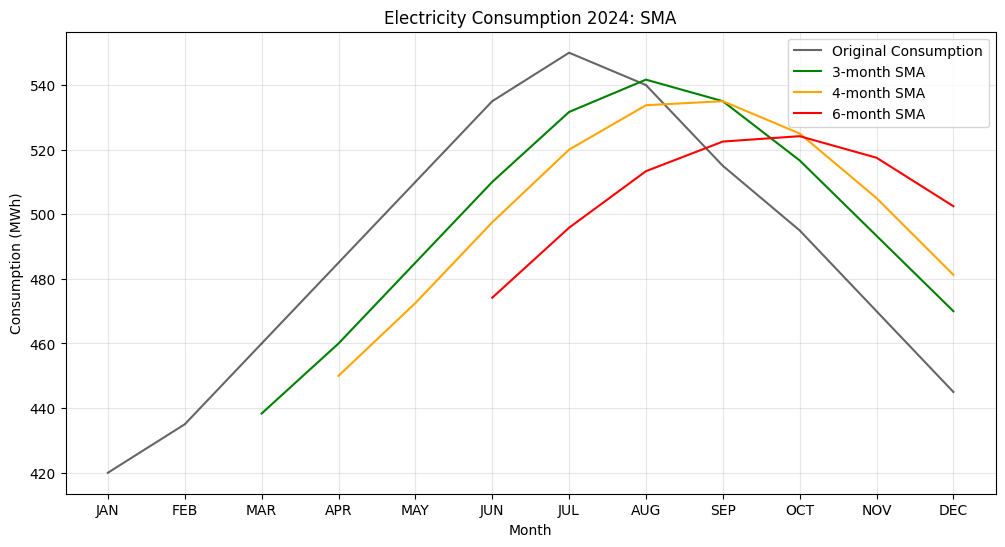

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(electricity_consumption.index, electricity_consumption['Consumption(MWh)'], label='Original Consumption', color='black', alpha=0.6)
plt.plot(electricity_consumption.index, electricity_consumption['SMA_3'], label='3-month SMA', color='green', linewidth=1.5)
plt.plot(electricity_consumption.index, electricity_consumption['SMA_4'], label='4-month SMA', color='orange', linewidth=1.5)
plt.plot(electricity_consumption.index, electricity_consumption['SMA_6'], label='6-month SMA', color='red', linewidth=1.5)

plt.title('Electricity Consumption 2024: SMA')
plt.xlabel('Month')
plt.ylabel('Consumption (MWh)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

(iv) Compare the smoothing effect of the three moving average windows and determine which window best represents the long-term consumption trend.

In [ ]:
# Comparison of Smoothing Effects:
#    3-Month SMA (Green): Provides the least smoothing. It follows the actual consumption peaks and valleys closely but still shows significant monthly fluctuations.
#    4-Month SMA (Orange): Offers moderate smoothing. It begins to "dampen" the peak seen in July.
#    6-Month SMA (Red): Provides the highest smoothing effect. It produces the flattest curve, effectively removing short-term volatility to show a more
#                       generalized view of the year’s energy usage.

# Best Representation of Long-Term Trend:
# The 6-month Moving Average best represents the long-term trend.

(v) Identify the months during which the electricity consumption remained above and below the 4-month moving average.

In [ ]:
# To determine if consumption is "above" or "below," we compare the Original Consumption (Black) to the 4-month SMA starting from April

# Key Observations:
# Summer Peak: From April to August, consumption remained consistently above the 4-month SMA, indicating a strong upward momentum in energy usage during the warmer months.
# Winter Decline: From September onwards, consumption fell below the 4-month SMA. This crossover signals a clear downward trend in energy demand toward the end of the year.